In [1]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import RelaxationTissueModel

microtorch_model = ModelMaker("Ball")
micro_ball_model = MicrotorchTissueModel(
    microtorch_model,
    parameters={"D": 2.0},
)

# micro_ball_model = RelaxationTissueModel(model=micro_ball_model, t2=0.1)



# micro_ball_model["T2"].optimize = False
# micro_ball_model["T2"].fit_flag = False
print(micro_ball_model)

No YAML configuration found for Ball model.
Falling back to parsing model name for compartments: ['Ball'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Ball
########### Compartments: ['Ball']
########### Parameter names: [['D']]
########### Parameter ranges: [[[0.001, 3]]]
-----------
Tissue model with 2 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  ------------
D                         2        1  True        True   (0.001, 3.0)
S0                        1        1  False       False  (0.0, 2.0)


In [2]:
from microtool.misst import _get_matlab_engine, set_misst_path, convert_acquisition_scheme
from microtool.tissue_model import TissueParameter
from microtool.misst import MisstTissueModel

# 2. Setup MATLAB engine & MISST
set_misst_path('/home/jgroot34/MISST/MISST_v0.95/MISST')
engine = _get_matlab_engine()

ball_parameters = {
    "diff": TissueParameter(
        value=2.0e-9,
        scale=1e-9,
        optimize=True,
        fit_flag=True,
        fit_bounds=(0.1e-9, 3.5e-9),
    )
}
MISST_ball_model = MisstTissueModel(name="Ball", parameters=ball_parameters)
MISST_ball_model["S0"].fit_flag = False
# MISST_ball_model = RelaxationTissueModel(model=Ball_MISST, t2=0.1)

# MISST_ball_model["T2"].optimize = False
# MISST_ball_model["T2"].fit_flag = False

print(MISST_ball_model)


Starting MATLAB engine...
MATLAB 2025b started.
Tissue model with 2 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  ----------------
diff                  2e-09    1e-09  True        True   (1e-10, 3.5e-09)
S0                    1        1      False       False  (0.0, inf)


In [3]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 2
block_size = n_directions + 1  # b0 + n_directions

shell_bvals = [1500, 2500]
shell_deltas = [0.0258, 0.0205]
shell_Deltas = [0.0434, 0.0331]
initial_te = 0.09

# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# TE and timing: one free value for each 7-measurement shell block.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Gradient magnitude: fix b0, then share one value across each shell's six DW measurements.
b0_mask = b_vals == 0
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

print("TE free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Timing free indices:",
      np.flatnonzero(initial_scheme["DiffusionPulseDuration"].optimize_mask))
print("Gradient free indices:",
      np.flatnonzero(magnitude.optimize_mask))

print(initial_scheme)


TE free indices: [0 7]
Timing free indices: [0 7]
Gradient free indices: [1 8]
Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                          0.0258                                        0.0434                            0.09
                          

In [4]:
micro_signal = micro_ball_model(initial_scheme)
print(micro_signal)

misst_signal = MISST_ball_model(initial_scheme)
print(misst_signal)


[1.         0.04978707 0.04978707 0.04978707 0.04978707 0.04978707
 0.04978707 1.         0.00673795 0.00673795 0.00673795 0.00673795
 0.00673795 0.00673795]
[1.         0.05081051 0.05081051 0.05081051 0.05081051 0.05081051
 0.05081051 1.         0.00702939 0.00702939 0.00702939 0.00702939
 0.00702939 0.00702939]


In [5]:
micro_jacobian = micro_ball_model.scaled_jacobian(initial_scheme)
print(micro_jacobian)

MISST_jacobian = MISST_ball_model.scaled_jacobian(initial_scheme)
print(MISST_jacobian)

[[ 0.        ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [ 0.        ]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]]
[[-0.        ]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.        ]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]]


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [6]:
# from microtool.monte_carlo.simulation import MonteCarloSimulation
# from scipy import stats

# micro_signal = np.asarray(micro_ball_model(initial_scheme))
# misst_signal = np.asarray(MISST_ball_model(initial_scheme))

# print("MicroTorch:", micro_signal[:10])
# print("MISST:", misst_signal[:10])
# print("Maximum signal difference:",
#       np.max(np.abs(micro_signal - misst_signal)))
# print("MISST / MicroTorch:",
#       np.divide(misst_signal, micro_signal,
#                 out=np.full_like(misst_signal, np.nan),
#                 where=micro_signal != 0)[:10])

# print("MISST fit parameters:", [
#     (name, p.value, p.scale, p.fit_flag, p.fit_bounds)
#     for name, p in MISST_ball_model.items()
# ])
# print("MicroTorch fit parameters:", [
#     (name, p.value, p.scale, p.fit_flag, p.fit_bounds)
#     for name, p in micro_ball_model.items()
# ])

# # loc is mean and scale is standard deviation
# noise_distribution = stats.norm(loc=0, scale=0.02)

# # Perform a Monte Carlo simulation using the initial scheme.
# simulation = MonteCarloSimulation(
#     initial_scheme,
#     micro_ball_model,
#     noise_distribution,
#     n_sim=100,
#     fit_options={"diff_step": 1e-4},
# )
# simulation.run()
# micro_initial = simulation.result


# # Perform a Monte Carlo simulation using the initial scheme.
# simulation = MonteCarloSimulation(
#     initial_scheme,
#     MISST_ball_model,
#     noise_distribution,
#     n_sim=100,
#     fit_options={"diff_step": 1e-4},
# )
# simulation.run()
# MISST_initial = simulation.result

# from matplotlib import pyplot as plt
# import numpy as np

# # Reference diffusion coefficient
# reference = micro_ball_model["D"].value


# # Extract D samples
# micro_initial_values = np.asarray(micro_initial["D"]).ravel()


# MISST_initial_values = (np.asarray(MISST_initial["diff"]).ravel())*1e9

# # Calculate RMSE
# micro_initial_rmse = np.sqrt(np.mean((micro_initial_values - reference) ** 2))

# MISST_initial_rmse = np.sqrt(np.mean((MISST_initial_values - reference) ** 2))

# print(f"RMSE: {micro_initial_rmse:.12g}")
# print("D estimates:", micro_initial_values[:10])
# print("Unique estimates:", np.unique(micro_initial_values).size)
# # Common histogram bins
# bins = np.linspace(0.5 * reference, 1.5 * reference, 25)

# # --------------------------------------------------
# # Plot 1: MICROtool
# # --------------------------------------------------
# plt.figure(figsize=(8, 5))

# plt.axvline(
#     reference,
#     color="black",
#     linestyle="--",
#     label="Reference"
# )

# plt.hist(
#     micro_initial_values,
#     bins=bins,
#     alpha=0.5,
#     label=f"Initial (RMSE={micro_initial_rmse:.4f})"
# )



# plt.xlabel("Diffusion coefficient D")
# plt.ylabel("Count")
# plt.title("MICROtool: Initial vs Optimized")
# plt.legend()
# plt.tight_layout()
# plt.show()


# # --------------------------------------------------
# # Plot 2: MISST
# # --------------------------------------------------
# plt.figure(figsize=(8, 5))

# plt.axvline(
#     reference,
#     color="black",
#     linestyle="--",
#     label="Reference"
# )

# plt.hist(
#     MISST_initial_values,
#     bins=bins,
#     alpha=0.5,
#     label=f"Initial (RMSE={MISST_initial_rmse:.4f})"
# )



# plt.xlabel("Diffusion coefficient D")
# plt.ylabel("Count")
# plt.title("MISST: Initial vs Optimized")
# plt.legend()
# plt.tight_layout()
# plt.show()

In [7]:
# from microtool.optimize import optimize_scheme

# micro_optimal_scheme, _ = optimize_scheme(initial_scheme, micro_ball_model, noise_variance=0.05, method="trust-constr", solver_options = {
#     "verbose": 2,
#     "maxiter": 150
# })

# MISST_optimal_scheme, _ = optimize_scheme(initial_scheme, MISST_ball_model, noise_variance=0.05, method="trust-constr", solver_options = {
#     "verbose": 2,
#     "maxiter": 150
# })


In [8]:
# print(micro_optimal_scheme)
# print(micro_optimal_scheme.b_values)

# print(MISST_optimal_scheme)
# print(MISST_optimal_scheme.b_values)

In [9]:
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme

import numpy as np
from microtool.optimize.loss_functions import compute_loss, gauss_loss


method = methods.SOMA()
micro_optimal_scheme, _ = optimize_scheme(
    initial_scheme, micro_ball_model, noise_variance=0.02, method=method
)

print("Second starting:")
MISST_optimal_scheme, _ = optimize_scheme(
    initial_scheme, MISST_ball_model, noise_variance=0.02, method=method
)   



Manually setted max fevals to: 60000
[SOMA] Starting Optimization
  Dimension (Nx)     : 8
  Population Size    : 50
  Max Migrations     : 100
  Max Fevals         : 60000
  Jumps per movement : 28
[SOMA Init] Initial Best Cost: inf | Initial Fevals: 50
----------------------------------------------------------------------
[SOMA] Mig 000/100 | Fevals: 001422/060000 | Best Cost: inf | Delta: +nan | 
[SOMA] Mig 001/100 | Fevals: 002794/060000 | Best Cost: 2.565833e+01 | Delta: +inf | 
[SOMA] Mig 002/100 | Fevals: 004166/060000 | Best Cost: 6.856278e-01 | Delta: +2.497e+01 | 
[SOMA] Mig 003/100 | Fevals: 005538/060000 | Best Cost: 5.954037e-02 | Delta: +6.261e-01 | 
[SOMA] Mig 004/100 | Fevals: 006910/060000 | Best Cost: 5.954037e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 005/100 | Fevals: 008282/060000 | Best Cost: 5.954037e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 006/100 | Fevals: 009654/060000 | Best Cost: 5.954037e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 007/100 | Fevals: 011026/060000 | Best C

In [10]:
print(micro_optimal_scheme)
print(micro_optimal_scheme.b_values)

print(MISST_optimal_scheme)
print(MISST_optimal_scheme.b_values)

Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                       0.0124987                                     0.040317                        0.0912851
                                        0.0351526                                 -2.57288               

In [11]:
print(micro_ball_model)

print(MISST_ball_model)

Tissue model with 2 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  ------------
D                         2        1  True        True   (0.001, 3.0)
S0                        1        1  False       False  (0.0, 2.0)
Tissue model with 2 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  ----------------
diff                  2e-09    1e-09  True        True   (1e-10, 3.5e-09)
S0                    1        1      False       False  (0.0, inf)


In [15]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats

# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

simulation = MonteCarloSimulation(
    initial_scheme,
    MISST_ball_model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
MISST_initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(MISST_optimal_scheme)
simulation.run()
MISST_optimal = simulation.result


# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    micro_ball_model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
micro_initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(micro_optimal_scheme)
simulation.run()
micro_optimal = simulation.result



Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:01<00:00, 724.98it/s]


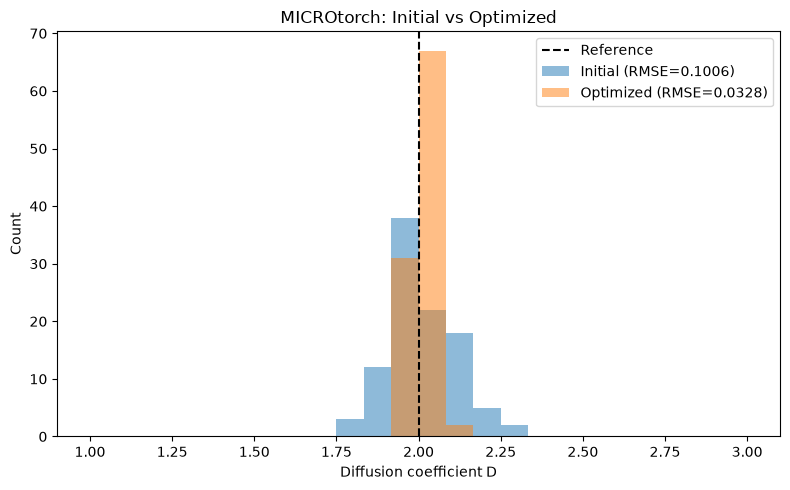

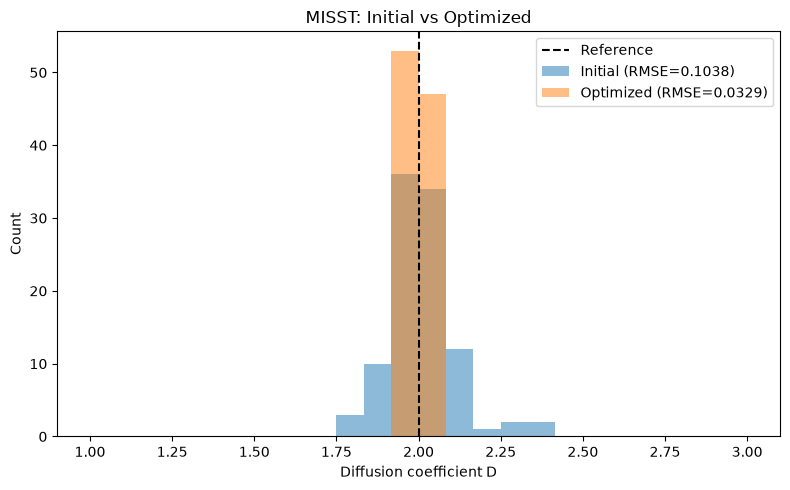

In [14]:
from matplotlib import pyplot as plt
import numpy as np

# Reference diffusion coefficient
reference = micro_ball_model["D"].value


# Extract D samples
micro_initial_values = np.asarray(micro_initial["D"]).ravel()
micro_optimal_values = np.asarray(micro_optimal["D"]).ravel()

MISST_initial_values = (np.asarray(MISST_initial["diff"]).ravel())*1e9
MISST_optimal_values = (np.asarray(MISST_optimal["diff"]).ravel())*1e9
# Calculate RMSE
micro_initial_rmse = np.sqrt(np.mean((micro_initial_values - reference) ** 2))
micro_optimal_rmse = np.sqrt(np.mean((micro_optimal_values - reference) ** 2))

MISST_initial_rmse = np.sqrt(np.mean((MISST_initial_values - reference) ** 2))
MISST_optimal_rmse = np.sqrt(np.mean((MISST_optimal_values - reference) ** 2))

# Common histogram bins
bins = np.linspace(0.5 * reference, 1.5 * reference, 25)

# --------------------------------------------------
# Plot 1: MICROtool
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.axvline(
    reference,
    color="black",
    linestyle="--",
    label="Reference"
)

plt.hist(
    micro_initial_values,
    bins=bins,
    alpha=0.5,
    label=f"Initial (RMSE={micro_initial_rmse:.4f})"
)

plt.hist(
    micro_optimal_values,
    bins=bins,
    alpha=0.5,
    label=f"Optimized (RMSE={micro_optimal_rmse:.4f})"
)

plt.xlabel("Diffusion coefficient D")
plt.ylabel("Count")
plt.title("MICROtorch: Initial vs Optimized")
plt.legend()
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Plot 2: MISST
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.axvline(
    reference,
    color="black",
    linestyle="--",
    label="Reference"
)

plt.hist(
    MISST_initial_values,
    bins=bins,
    alpha=0.5,
    label=f"Initial (RMSE={MISST_initial_rmse:.4f})"
)

plt.hist(
    MISST_optimal_values,
    bins=bins,
    alpha=0.5,
    label=f"Optimized (RMSE={MISST_optimal_rmse:.4f})"
)

plt.xlabel("Diffusion coefficient D")
plt.ylabel("Count")
plt.title("MISST: Initial vs Optimized")
plt.legend()
plt.tight_layout()
plt.show()